# Task 1: Car Colour Detection and Traffic Analysis

## Task Objective

The objective of this internship task is to develop a computer vision
module capable of detecting cars in traffic images, estimating whether
a detected car is blue, counting detected cars, and counting people
present in the traffic scene.

According to the task requirement:

- Blue cars must be displayed using red bounding boxes.
- Other colour cars must be displayed using blue bounding boxes.
- The total number of detected cars must be calculated.
- The number of detected people must also be displayed.

This notebook documents the experimental process before integrating
the feature into the existing computer vision project.

## Internship Task Requirement

This experiment is implemented as an additional computer vision module
within the existing training project repository.

The experiment consists of two main stages:

1. Object detection for locating cars and people.
2. HSV-based colour analysis for estimating whether a detected car is blue.

A pretrained YOLO object detector is used for object localization.

The colour classification stage is experimentally evaluated using
different blue-pixel ratio thresholds.

In [14]:
!pip install -q ultralytics opencv-python

In [15]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO

print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)

OpenCV Version: 4.13.0
NumPy Version: 2.0.2


In [16]:
model = YOLO("yolov8n.pt")

print("YOLOv8 Nano model loaded successfully.")

YOLOv8 Nano model loaded successfully.


## Object Detection Model

A pretrained YOLOv8 Nano model is used to locate objects in traffic
images.

The pretrained detector is used only for object localization. The
blue-car classification logic is implemented separately using HSV
colour analysis.

The main object classes required in this experiment are:

- Person
- Car

The colour of each detected car is analysed after extracting its
region of interest.

The YOLO model used in this experiment was not trained from scratch.
Pretrained model weights are used for object detection.

In [19]:
image_paths = []

for dirname, _, filenames in os.walk("/kaggle/input"):

    for filename in filenames:

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            path = os.path.join(
                dirname,
                filename
            )

            image_paths.append(path)

            print(path)

print(
    "\nTotal images found:",
    len(image_paths)
)

/kaggle/input/datasets/priti1122/traffic/traffic_04.png
/kaggle/input/datasets/priti1122/traffic/traffic_02.jpg
/kaggle/input/datasets/priti1122/traffic/traffic_03.jpg
/kaggle/input/datasets/priti1122/traffic/traffic_05.png
/kaggle/input/datasets/priti1122/traffic/traffic_01.jpg

Total images found: 5


In [20]:
if len(image_paths) == 0:
    raise ValueError(
        "No traffic images found in Kaggle input."
    )

images = []

for image_path in image_paths:

    image = cv2.imread(image_path)

    if image is not None:

        images.append({
            "path": image_path,
            "image": image
        })

print(
    "Successfully loaded images:",
    len(images)
)

Successfully loaded images: 5


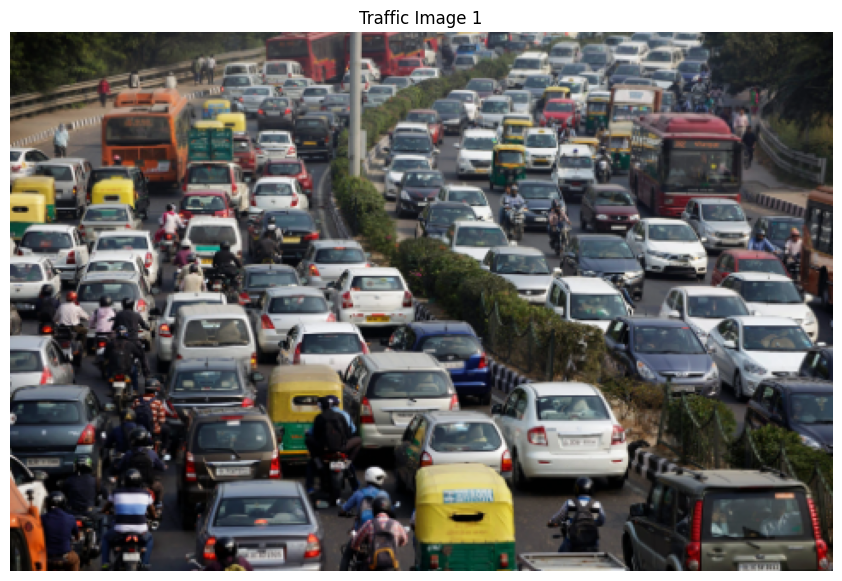

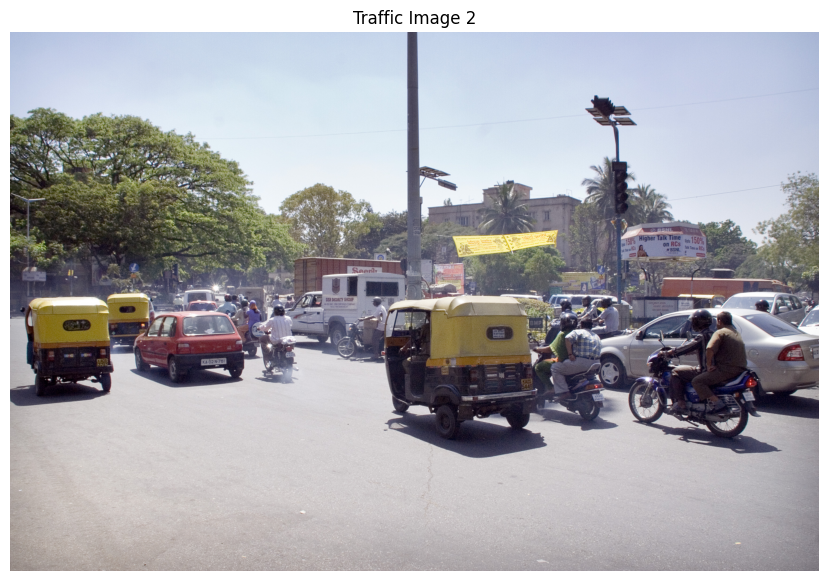

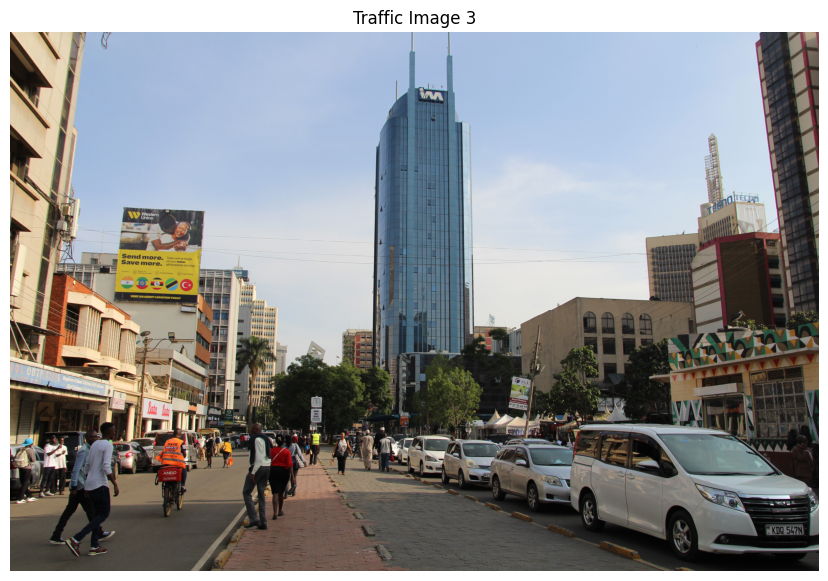

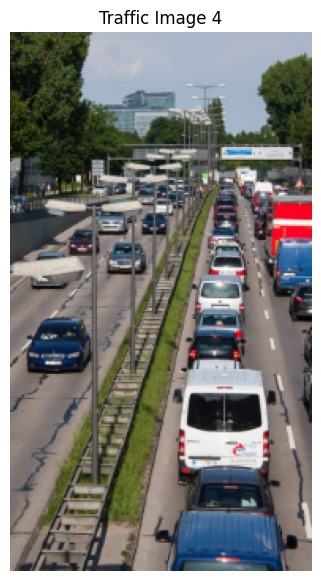

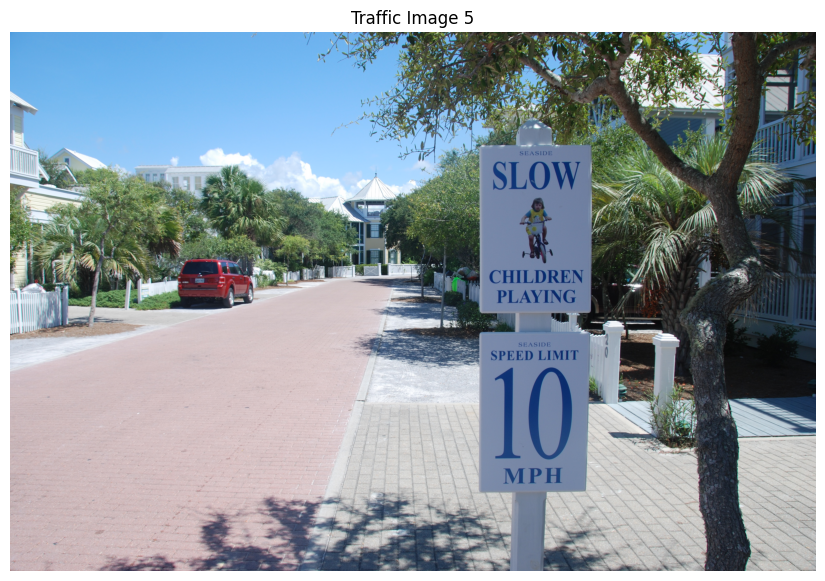

In [21]:
for index, image_data in enumerate(images):

    image = image_data["image"]

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 7))

    plt.imshow(image_rgb)

    plt.title(
        f"Traffic Image {index + 1}"
    )

    plt.axis("off")

    plt.show()

## Input Traffic Images

Multiple traffic images are used in this experiment to observe object
detection and colour classification under different traffic scenes.

Using multiple images reduces dependency on the characteristics of a
single test image.

The images are used for experimental evaluation and are not used to
train the pretrained YOLO object detector.

In [22]:
all_detection_results = []

for image_index, image_data in enumerate(images):

    image = image_data["image"]

    results = model(
        image,
        verbose=False
    )

    image_data["results"] = results

    for result in results:

        for box in result.boxes:

            class_id = int(
                box.cls[0]
            )

            confidence = float(
                box.conf[0]
            )

            class_name = model.names[
                class_id
            ]

            all_detection_results.append({
                "Image": image_index + 1,
                "Class ID": class_id,
                "Object": class_name,
                "Confidence": round(
                    confidence,
                    4
                )
            })

detection_df = pd.DataFrame(
    all_detection_results
)

detection_df

,Image,Class ID,Object,Confidence
0,1,2,car,0.8533
1,1,5,bus,0.8405
2,1,2,car,0.7969
3,1,2,car,0.7944
4,1,2,car,0.7603
...,...,...,...,...
112,4,2,car,0.2509
113,5,2,car,0.6527
114,5,7,truck,0.4548
115,5,1,bicycle,0.3289


Object
car              64
person           27
truck             9
bus               8
motorcycle        5
bicycle           2
traffic light     1
skateboard        1
Name: count, dtype: int64


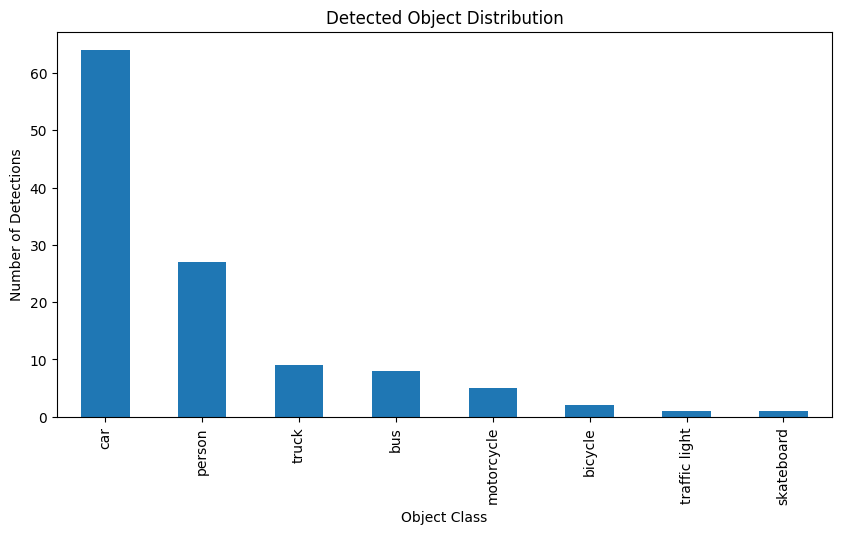

In [23]:
if not detection_df.empty:

    object_counts = (
        detection_df["Object"]
        .value_counts()
    )

    print(object_counts)

    plt.figure(figsize=(10, 5))

    object_counts.plot(
        kind="bar"
    )

    plt.title(
        "Detected Object Distribution"
    )

    plt.xlabel(
        "Object Class"
    )

    plt.ylabel(
        "Number of Detections"
    )

    plt.show()

else:

    print(
        "No objects detected."
    )

## Car Region of Interest Extraction

After object detection, detections classified as cars are selected.

The bounding-box coordinates of each detected car are used to crop the
car region from the original image.

These cropped regions are called Regions of Interest (ROI).

Colour analysis is performed on each car ROI instead of the complete
traffic image. This reduces the influence of unrelated areas of the
traffic scene.

In [24]:
car_rois = []

for image_index, image_data in enumerate(images):

    image = image_data["image"]

    results = image_data["results"]

    for result in results:

        for box in result.boxes:

            class_id = int(
                box.cls[0]
            )

            confidence = float(
                box.conf[0]
            )

            if (
                class_id == 2
                and confidence >= 0.50
            ):

                x1, y1, x2, y2 = map(
                    int,
                    box.xyxy[0]
                )

                car_roi = image[
                    y1:y2,
                    x1:x2
                ]

                if car_roi.size > 0:

                    car_rois.append({
                        "image_id": image_index + 1,
                        "roi": car_roi,
                        "confidence": confidence
                    })

print(
    "Total car ROIs:",
    len(car_rois)
)

Total car ROIs: 32


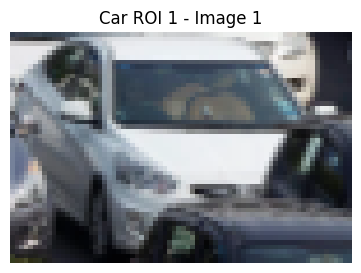

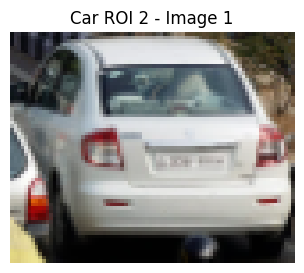

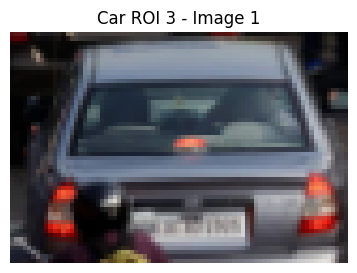

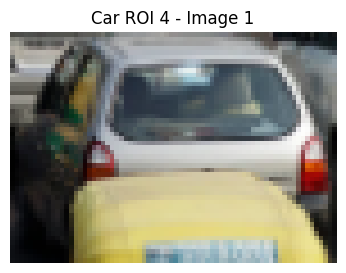

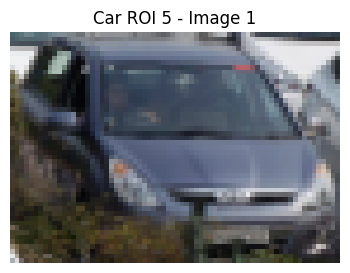

...

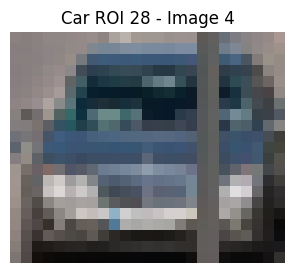

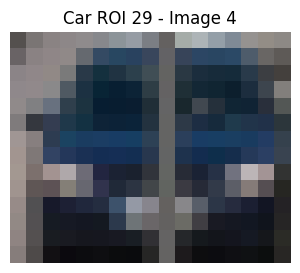

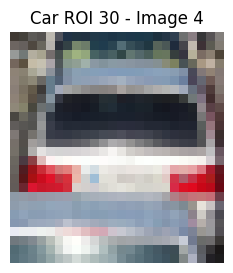

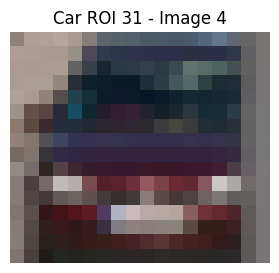

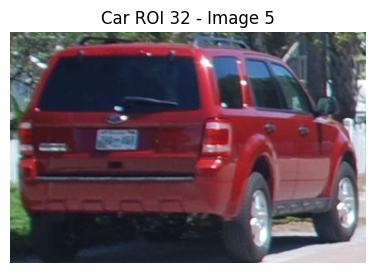

In [25]:
for index, car_data in enumerate(car_rois):

    car_roi = car_data["roi"]

    car_rgb = cv2.cvtColor(
        car_roi,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(5, 3))

    plt.imshow(car_rgb)

    plt.title(
        f"Car ROI {index + 1} "
        f"- Image {car_data['image_id']}"
    )

    plt.axis("off")

    plt.show()

## RGB vs HSV Colour Analysis

RGB represents an image using red, green, and blue intensity values.

Lighting and brightness variations may influence RGB colour values.

HSV separates colour information into:

- Hue
- Saturation
- Value

Hue provides useful information for defining a specific colour range.

Therefore, HSV colour space is used for the blue-car classification
experiment.

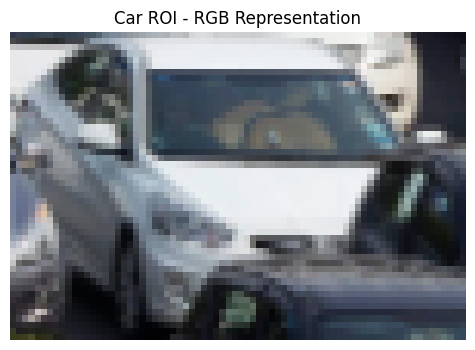

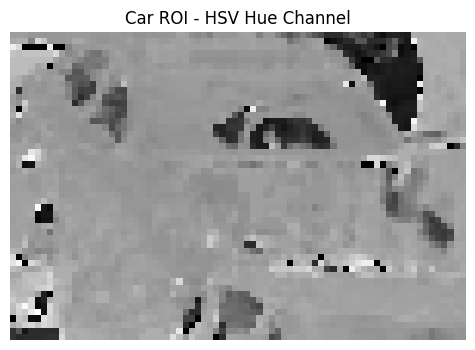

In [26]:
if len(car_rois) > 0:

    sample_car = car_rois[0]["roi"]

    sample_rgb = cv2.cvtColor(
        sample_car,
        cv2.COLOR_BGR2RGB
    )

    sample_hsv = cv2.cvtColor(
        sample_car,
        cv2.COLOR_BGR2HSV
    )

    plt.figure(figsize=(7, 4))

    plt.imshow(sample_rgb)

    plt.title(
        "Car ROI - RGB Representation"
    )

    plt.axis("off")

    plt.show()


    plt.figure(figsize=(7, 4))

    plt.imshow(
        sample_hsv[:, :, 0],
        cmap="gray"
    )

    plt.title(
        "Car ROI - HSV Hue Channel"
    )

    plt.axis("off")

    plt.show()

else:

    print(
        "No car ROI available."
    )

In [27]:
def calculate_blue_ratio(car_image):

    if (
        car_image is None
        or car_image.size == 0
    ):
        return 0.0

    hsv_image = cv2.cvtColor(
        car_image,
        cv2.COLOR_BGR2HSV
    )

    lower_blue = np.array(
        [90, 50, 50]
    )

    upper_blue = np.array(
        [140, 255, 255]
    )

    blue_mask = cv2.inRange(
        hsv_image,
        lower_blue,
        upper_blue
    )

    blue_pixels = cv2.countNonZero(
        blue_mask
    )

    total_pixels = (
        car_image.shape[0]
        * car_image.shape[1]
    )

    if total_pixels == 0:
        return 0.0

    blue_ratio = (
        blue_pixels
        / total_pixels
    )

    return blue_ratio

In [28]:
blue_ratio_results = []

for index, car_data in enumerate(car_rois):

    blue_ratio = calculate_blue_ratio(
        car_data["roi"]
    )

    blue_ratio_results.append({
        "Car": f"Car {index + 1}",
        "Image": car_data["image_id"],
        "Blue Pixel Ratio": round(
            blue_ratio,
            4
        )
    })

blue_ratio_df = pd.DataFrame(
    blue_ratio_results
)

blue_ratio_df

,Car,Image,Blue Pixel Ratio
0,Car 1,1,0.2324
1,Car 2,1,0.0729
2,Car 3,1,0.2799
3,Car 4,1,0.1174
4,Car 5,1,0.3770
5,Car 6,1,0.1074
6,Car 7,1,0.3287
7,Car 8,1,0.1729
8,Car 9,1,0.1384
9,Car 10,1,0.2838


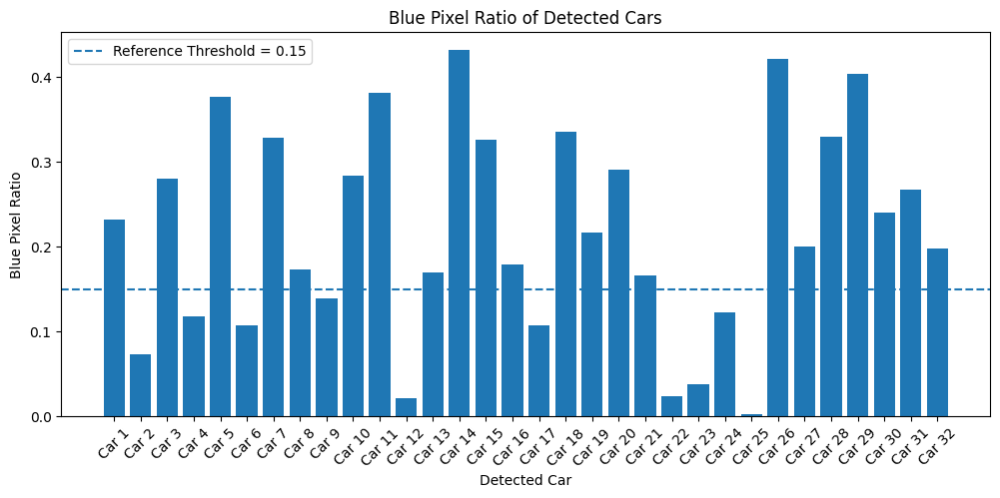

In [29]:
if not blue_ratio_df.empty:

    plt.figure(figsize=(12, 5))

    plt.bar(
        blue_ratio_df["Car"],
        blue_ratio_df[
            "Blue Pixel Ratio"
        ]
    )

    plt.axhline(
        y=0.15,
        linestyle="--",
        label="Reference Threshold = 0.15"
    )

    plt.title(
        "Blue Pixel Ratio of Detected Cars"
    )

    plt.xlabel(
        "Detected Car"
    )

    plt.ylabel(
        "Blue Pixel Ratio"
    )

    plt.xticks(
        rotation=45
    )

    plt.legend()

    plt.show()

## Blue Colour Threshold Experiment

The blue-pixel ratio represents the proportion of pixels inside a
detected car region that fall within the selected HSV blue range.

Five candidate thresholds are evaluated:

- 0.05
- 0.10
- 0.15
- 0.20
- 0.25

Lower thresholds may incorrectly classify cars as blue because of
reflections or background pixels.

Higher thresholds may fail to identify partially visible or poorly
illuminated blue cars.

The experiment compares the classification behaviour of different
threshold values.

In [30]:
thresholds = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25
]

threshold_results = []

for threshold in thresholds:

    predicted_blue_cars = 0

    for car_data in car_rois:

        blue_ratio = calculate_blue_ratio(
            car_data["roi"]
        )

        if blue_ratio > threshold:

            predicted_blue_cars += 1

    threshold_results.append({
        "Threshold": threshold,
        "Predicted Blue Cars":
            predicted_blue_cars
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df

,Threshold,Predicted Blue Cars
0,0.05,28
1,0.10,27
2,0.15,22
3,0.20,16
4,0.25,13


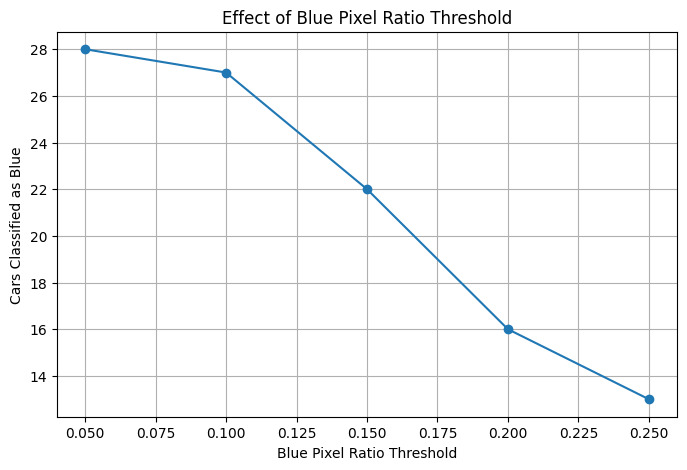

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df[
        "Predicted Blue Cars"
    ],
    marker="o"
)

plt.title(
    "Effect of Blue Pixel Ratio Threshold"
)

plt.xlabel(
    "Blue Pixel Ratio Threshold"
)

plt.ylabel(
    "Cars Classified as Blue"
)

plt.grid(True)

plt.show()

In [32]:
actual_blue_car_counts = {
    1: 2,
    2: 1,
    3: 3
}

In [33]:
actual_blue_car_counts = {
    1: 0,
    2: 0,
    3: 0,
    4: 0,
    5: 0
}

print(
    "Manual blue-car labels:",
    actual_blue_car_counts
)

Manual blue-car labels: {1: 0, 2: 0, 3: 0, 4: 0, 5: 0}


In [34]:
threshold_evaluation = []

for threshold in thresholds:

    total_actual = 0

    total_predicted = 0

    for image_id in actual_blue_car_counts:

        actual_count = (
            actual_blue_car_counts[
                image_id
            ]
        )

        predicted_count = 0

        for car_data in car_rois:

            if (
                car_data["image_id"]
                == image_id
            ):

                blue_ratio = (
                    calculate_blue_ratio(
                        car_data["roi"]
                    )
                )

                if blue_ratio > threshold:

                    predicted_count += 1

        total_actual += actual_count

        total_predicted += predicted_count

    absolute_error = abs(
        total_actual
        - total_predicted
    )

    threshold_evaluation.append({
        "Threshold": threshold,
        "Actual Blue Cars": total_actual,
        "Predicted Blue Cars":
            total_predicted,
        "Absolute Error": absolute_error
    })

threshold_evaluation_df = pd.DataFrame(
    threshold_evaluation
)

threshold_evaluation_df

,Threshold,Actual Blue Cars,Predicted Blue Cars,Absolute Error
0,0.05,0,28,28
1,0.10,0,27,27
2,0.15,0,22,22
3,0.20,0,16,16
4,0.25,0,13,13


In [35]:
best_result = (
    threshold_evaluation_df
    .sort_values(
        by=[
            "Absolute Error",
            "Threshold"
        ]
    )
    .iloc[0]
)

SELECTED_THRESHOLD = float(
    best_result["Threshold"]
)

print(
    "Selected Threshold:",
    SELECTED_THRESHOLD
)

print(
    "Minimum Absolute Error:",
    int(
        best_result[
            "Absolute Error"
        ]
    )
)

Selected Threshold: 0.25
Minimum Absolute Error: 13


## Threshold Selection

The candidate thresholds were compared with manually observed blue-car
counts from the test traffic images.

Absolute count error was calculated as the difference between the total
manually observed blue-car count and the total predicted blue-car count.

The threshold with the lowest absolute count error was selected for the
final experiment.

This threshold is an experimental value for the current traffic-image
collection and may require further evaluation on a larger labelled
dataset.

In [36]:
def is_blue_car(
    car_image,
    threshold=SELECTED_THRESHOLD
):

    blue_ratio = calculate_blue_ratio(
        car_image
    )

    return blue_ratio > threshold

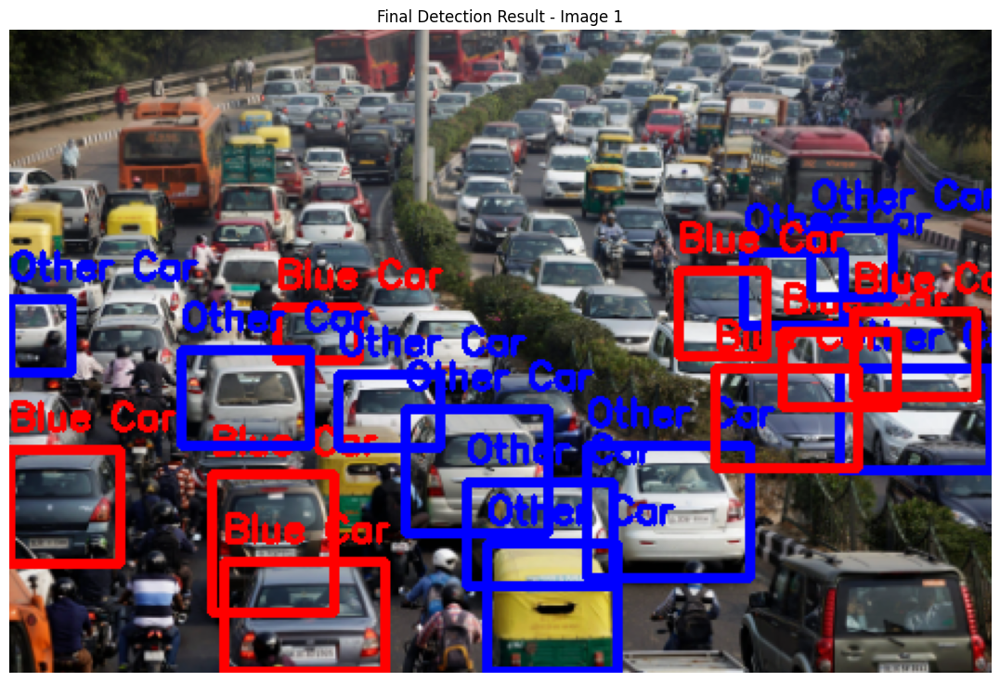

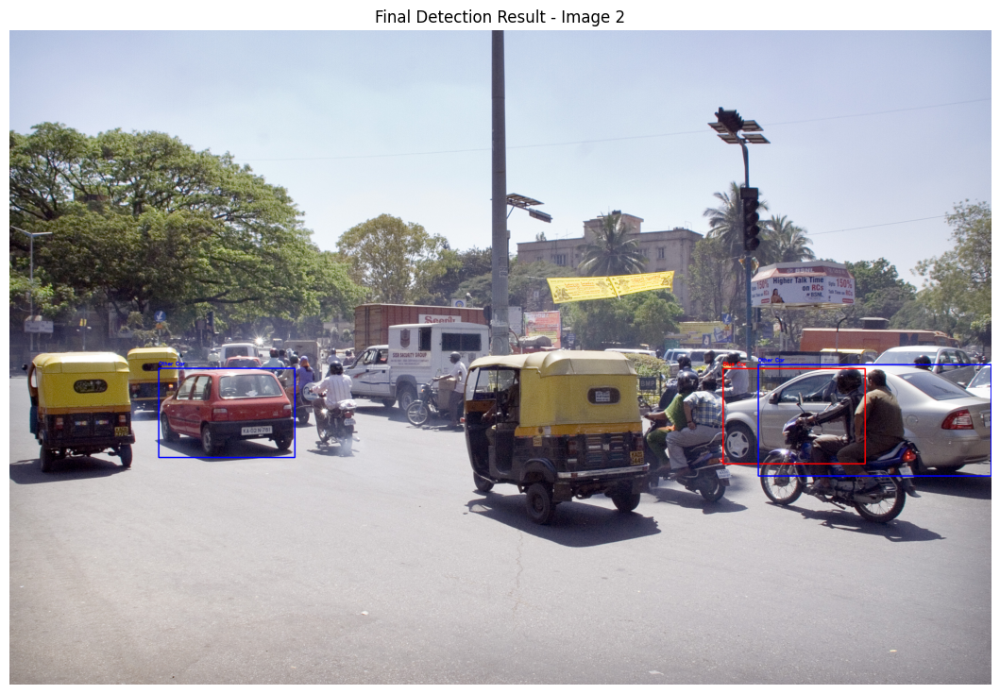

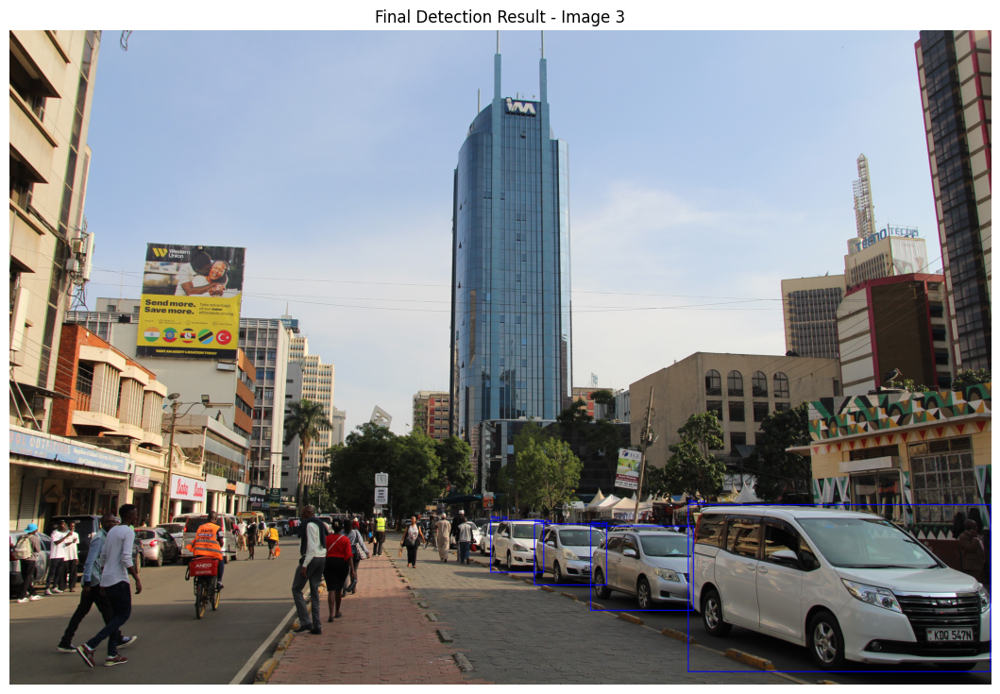

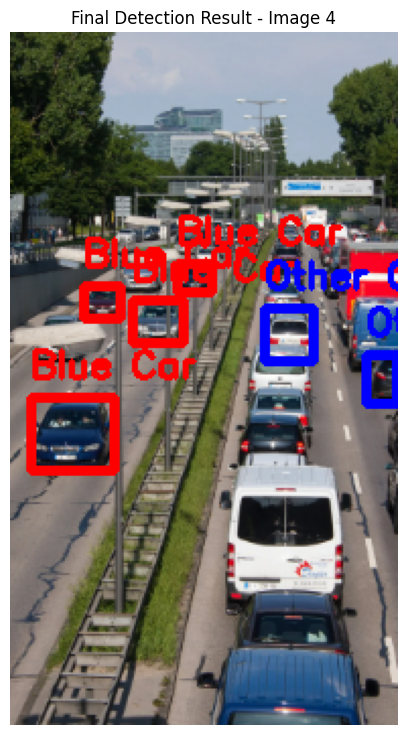

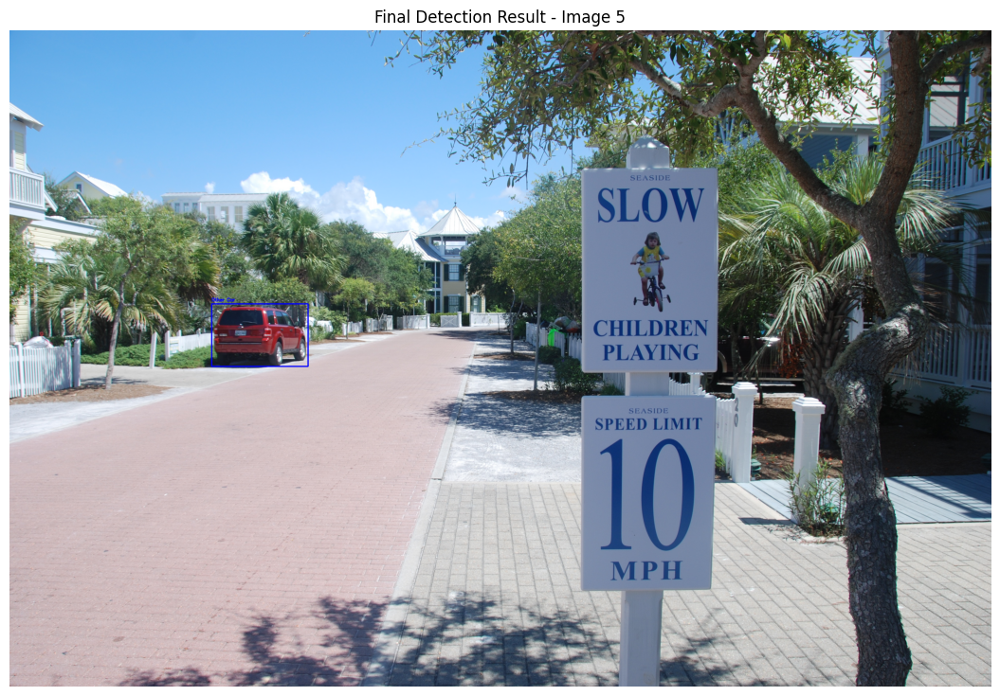

In [37]:
final_results = []

for image_index, image_data in enumerate(images):

    image = image_data["image"]

    results = image_data["results"]

    output_image = image.copy()

    car_count = 0

    blue_car_count = 0

    people_count = 0

    for result in results:

        for box in result.boxes:

            class_id = int(
                box.cls[0]
            )

            confidence = float(
                box.conf[0]
            )

            if confidence < 0.50:
                continue

            x1, y1, x2, y2 = map(
                int,
                box.xyxy[0]
            )

            if class_id == 2:

                car_count += 1

                car_roi = image[
                    y1:y2,
                    x1:x2
                ]

                blue_car = is_blue_car(
                    car_roi
                )

                if blue_car:

                    blue_car_count += 1

                    rectangle_color = (
                        0,
                        0,
                        255
                    )

                    label = "Blue Car"

                else:

                    rectangle_color = (
                        255,
                        0,
                        0
                    )

                    label = "Other Car"

                cv2.rectangle(
                    output_image,
                    (x1, y1),
                    (x2, y2),
                    rectangle_color,
                    3
                )

                cv2.putText(
                    output_image,
                    label,
                    (
                        x1,
                        max(y1 - 10, 20)
                    ),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    rectangle_color,
                    2
                )

            elif class_id == 0:

                people_count += 1

    other_car_count = (
        car_count
        - blue_car_count
    )

    final_results.append({
        "Image": image_index + 1,
        "Total Cars": car_count,
        "Blue Cars": blue_car_count,
        "Other Cars": other_car_count,
        "People": people_count
    })

    output_rgb = cv2.cvtColor(
        output_image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(15, 9))

    plt.imshow(output_rgb)

    plt.title(
        f"Final Detection Result "
        f"- Image {image_index + 1}"
    )

    plt.axis("off")

    plt.show()

In [38]:
final_results_df = pd.DataFrame(
    final_results
)

final_results_df

,Image,Total Cars,Blue Cars,Other Cars,People
0,1,18,8,10,1
1,2,3,1,2,2
2,3,4,0,4,5
3,4,6,4,2,0
4,5,1,0,1,0


In [39]:
print(
    "Total Cars Detected:",
    final_results_df[
        "Total Cars"
    ].sum()
)

print(
    "Total Blue Cars:",
    final_results_df[
        "Blue Cars"
    ].sum()
)

print(
    "Total Other Cars:",
    final_results_df[
        "Other Cars"
    ].sum()
)

print(
    "Total People Detected:",
    final_results_df[
        "People"
    ].sum()
)

Total Cars Detected: 32
Total Blue Cars: 13
Total Other Cars: 19
Total People Detected: 8


## Car Counting

The total car count is calculated using YOLO detections classified as
the car object class with a confidence score of at least 0.50.

Each accepted car detection increments the car counter.

HSV-based colour analysis is then used to classify each detected car as:

- Blue car
- Other colour car

## Person Counting

The pretrained YOLO model uses class ID 0 for the person class.

Each person detection with a confidence score of at least 0.50
increments the people counter.

The final count represents the number of detected people visible in
each traffic image.

## Limitations

The current experiment has several limitations:

1. Vehicle colour estimation may be influenced by lighting conditions.
2. Reflections may introduce blue pixels into non-blue vehicles.
3. Small or partially visible cars may have inaccurate colour estimates.
4. HSV colour ranges are manually defined.
5. Object localization depends on the pretrained YOLO model.
6. Occluded people and vehicles may not be detected.
7. Background pixels inside vehicle bounding boxes may influence colour
   classification.
8. The experimental threshold is evaluated on a small test-image
   collection.

Future improvements may include a trained vehicle colour classifier,
vehicle segmentation, and evaluation using a larger labelled vehicle
colour dataset.

## Conclusion

This experiment developed a traffic analysis module for car and person
detection.

A pretrained YOLOv8 Nano object detector was used to locate cars and
people. The YOLO model was not trained from scratch in this experiment.

Detected car regions were extracted and analysed using HSV colour space.
The blue-pixel ratio of each car region was calculated.

Multiple blue-pixel ratio thresholds were experimentally compared using
manually observed blue-car counts from the test traffic images.

The selected experimental threshold was used to classify detected cars.
Blue cars are displayed using red bounding boxes, while other colour
cars are displayed using blue bounding boxes according to the internship
task requirement.

The system also calculates the number of detected cars and people.

The experimental logic will be integrated into the Streamlit GUI of the
existing computer vision project.